# Anxiety Group Comparison: Day 1 Pre vs. Day 1 Post vs. Day 2 Pre Sentiment

This notebook compares the compound sentiment scores of the High Anxiety (`GAD-7 > 10`) vs. Low Anxiety (`GAD-7 < 4`) groups across three timepoints:
1. **Day 1 Before** (`day_1_pre_compound`)
2. **Day 1 After** (`day_1_post_compound`)
3. **Day 2 Before** (`day_2_pre_compound`)

We evaluate how sentiment scores shift in response to the task and across days for both groups.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")


In [2]:
# Load Data
df_nlp = pd.read_csv('../data/free_recall_nlp.csv')
df_survey = pd.read_csv('../data/survey.csv')

# Merge on Sub
df = pd.merge(df_nlp, df_survey, on='Sub')

# Drop rows with missing values in the key compound score columns
df = df.dropna(subset=['day_1_pre_compound', 'day_1_post_compound', 'day_2_pre_compound'])

# Ensure GAD7 is numeric
df['GAD7'] = pd.to_numeric(df['GAD7'], errors='coerce')


In [3]:
# Define Groups matching 02_free_recall_extremes.ipynb:
# Anxious (High): GAD-7 > 10
top5_anxious = df[(df['GAD7'] > 10) & (df['GAD7'] < 20)].sort_values(by=['GAD7', 'Sub'], ascending=[False, True]).copy()
top5_anxious['Group'] = 'Anxious'

# Non-Anxious (Low): GAD-7 < 4
bottom5_non_anxious = df[df['GAD7'] < 4].sort_values(by=['GAD7', 'Sub'], ascending=[True, True]).copy()
bottom5_non_anxious['Group'] = 'Non-Anxious'

# Combine the groups
df_groups = pd.concat([top5_anxious, bottom5_non_anxious])

print(f"=== Anxious Group (GAD-7 > 10, N={len(top5_anxious)}) ===")
print(top5_anxious[['Sub', 'GAD7', 'day_1_pre_compound', 'day_1_post_compound', 'day_2_pre_compound']])

print(f"\n=== Non-Anxious Group (GAD-7 < 4, N={len(bottom5_non_anxious)}) ===")
print(bottom5_non_anxious[['Sub', 'GAD7', 'day_1_pre_compound', 'day_1_post_compound', 'day_2_pre_compound']])


=== Anxious Group (GAD-7 > 10, N=11) ===
    Sub  GAD7  day_1_pre_compound  day_1_post_compound  day_2_pre_compound
42   52    19              0.3158               0.1779              0.3744
3    10    18              0.6096              -0.4330              0.8013
32   41    17             -0.8905               0.7548             -0.4097
21   29    16             -0.2473               0.7501              0.9575
64   75    15             -0.2782               0.4767              0.9100
30   38    14              0.2684              -0.2709              0.1027
40   49    13             -0.8472              -0.1546              0.4588
54   65    13              0.4215               0.0000             -0.4767
17   24    12              0.4331               0.9831              0.9045
57   68    12             -0.7096               0.8537             -0.3818
29   37    11             -0.5940              -0.4588             -0.8580

=== Non-Anxious Group (GAD-7 < 4, N=14) ===
    Sub  GAD7 

In [4]:
# Run Statistical Tests
print("=== STATISTICAL COMPARISONS ===\n")

# Within Anxious Group
t_anx_1, p_anx_1 = stats.ttest_rel(top5_anxious['day_1_pre_compound'], top5_anxious['day_1_post_compound'])
t_anx_2, p_anx_2 = stats.ttest_rel(top5_anxious['day_1_post_compound'], top5_anxious['day_2_pre_compound'])
t_anx_3, p_anx_3 = stats.ttest_rel(top5_anxious['day_1_pre_compound'], top5_anxious['day_2_pre_compound'])

print("Within Anxious Group:")
print(f"  Day 1 Pre vs Day 1 Post: t = {t_anx_1:.3f}, p = {p_anx_1:.4f}")
print(f"  Day 1 Post vs Day 2 Pre: t = {t_anx_2:.3f}, p = {p_anx_2:.4f}")
print(f"  Day 1 Pre vs Day 2 Pre:  t = {t_anx_3:.3f}, p = {p_anx_3:.4f}\n")

# Within Non-Anxious Group
t_non_1, p_non_1 = stats.ttest_rel(bottom5_non_anxious['day_1_pre_compound'], bottom5_non_anxious['day_1_post_compound'])
t_non_2, p_non_2 = stats.ttest_rel(bottom5_non_anxious['day_1_post_compound'], bottom5_non_anxious['day_2_pre_compound'])
t_non_3, p_non_3 = stats.ttest_rel(bottom5_non_anxious['day_1_pre_compound'], bottom5_non_anxious['day_2_pre_compound'])

print("Within Non-Anxious Group:")
print(f"  Day 1 Pre vs Day 1 Post: t = {t_non_1:.3f}, p = {p_non_1:.4f}")
print(f"  Day 1 Post vs Day 2 Pre: t = {t_non_2:.3f}, p = {p_non_2:.4f}")
print(f"  Day 1 Pre vs Day 2 Pre:  t = {t_non_3:.3f}, p = {p_non_3:.4f}\n")

# Between Groups at each timepoint
t_b1, p_b1 = stats.ttest_ind(top5_anxious['day_1_pre_compound'], bottom5_non_anxious['day_1_pre_compound'])
t_b2, p_b2 = stats.ttest_ind(top5_anxious['day_1_post_compound'], bottom5_non_anxious['day_1_post_compound'])
t_b3, p_b3 = stats.ttest_ind(top5_anxious['day_2_pre_compound'], bottom5_non_anxious['day_2_pre_compound'])

print("Between Groups (Anxious vs Non-Anxious):")
print(f"  Day 1 Pre:  t = {t_b1:.3f}, p = {p_b1:.4f}")
print(f"  Day 1 Post: t = {t_b2:.3f}, p = {p_b2:.4f}")
print(f"  Day 2 Pre:  t = {t_b3:.3f}, p = {p_b3:.4f}")


=== STATISTICAL COMPARISONS ===

Within Anxious Group:
  Day 1 Pre vs Day 1 Post: t = -1.462, p = 0.1743
  Day 1 Post vs Day 2 Pre: t = 0.120, p = 0.9072
  Day 1 Pre vs Day 2 Pre:  t = -1.718, p = 0.1166

Within Non-Anxious Group:
  Day 1 Pre vs Day 1 Post: t = -1.566, p = 0.1415
  Day 1 Post vs Day 2 Pre: t = 1.477, p = 0.1636
  Day 1 Pre vs Day 2 Pre:  t = -0.122, p = 0.9045

Between Groups (Anxious vs Non-Anxious):
  Day 1 Pre:  t = -2.483, p = 0.0207
  Day 1 Post: t = -1.592, p = 0.1250
  Day 2 Pre:  t = -0.503, p = 0.6200


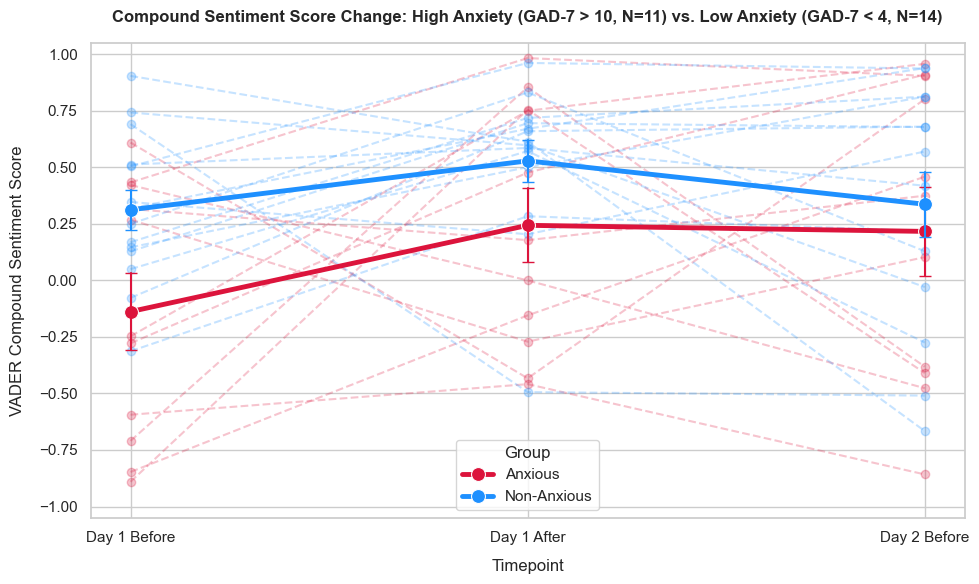

In [5]:
# Melt the dataframe for seaborn plotting
df_melted = df_groups.melt(
    id_vars=['Sub', 'GAD7', 'Group'],
    value_vars=['day_1_pre_compound', 'day_1_post_compound', 'day_2_pre_compound'],
    var_name='Timepoint',
    value_name='CompoundScore'
)

df_melted['Timepoint'] = df_melted['Timepoint'].map({
    'day_1_pre_compound': 'Day 1 Before',
    'day_1_post_compound': 'Day 1 After',
    'day_2_pre_compound': 'Day 2 Before'
})

plt.figure(figsize=(10, 6))

# Plot individual subject lines (faded)
for sub in df_groups['Sub'].unique():
    sub_data = df_melted[df_melted['Sub'] == sub]
    group = sub_data['Group'].iloc[0]
    color = 'crimson' if group == 'Anxious' else 'dodgerblue'
    plt.plot(sub_data['Timepoint'], sub_data['CompoundScore'], color=color, alpha=0.25, linestyle='--', marker='o')

# Plot group average line plots with standard errors
sns.lineplot(
    x='Timepoint',
    y='CompoundScore',
    hue='Group',
    data=df_melted,
    palette={'Anxious': 'crimson', 'Non-Anxious': 'dodgerblue'},
    linewidth=3.5,
    marker='o',
    markersize=10,
    err_style='bars',
    errorbar='se',
    err_kws={'capsize': 4}
)

plt.title(f'Compound Sentiment Score Change: High Anxiety (GAD-7 > 10, N={len(top5_anxious)}) vs. Low Anxiety (GAD-7 < 4, N={len(bottom5_non_anxious)})', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Timepoint', fontsize=12, labelpad=10)
plt.ylabel('VADER Compound Sentiment Score', fontsize=12, labelpad=10)
plt.ylim(-1.05, 1.05)
plt.legend(title='Group', frameon=True)
plt.tight_layout()
plt.savefig('../data/anxiety_comparison_plot.png', dpi=300)
plt.show()
